# EdTech Experiment & Causal Analysis

## Project Overview

This project studies whether changes introduced by a fictional coaching institute actually improve learner outcomes.

The project has two main parts:

1. Design and analyze an A/B experiment for a new initiative called Personalised Weekly Progress Feedback.
2. Estimate the impact of a previous non-experimental change using Difference-in-Differences.

The analysis focuses on course completion, assessment performance, drop-off, attendance, and assignment submission.

Because an experiment dataset was not supplied with the project page, the analysis dataset used in this project is synthetic and was created to reproduce the data structure and quality issues described in the project brief.

In [1]:
import pandas as pd

raw_df = pd.read_csv("../data/raw_learner_activity.csv")

print("Shape:", raw_df.shape)
print("\nColumns:")
print(raw_df.columns.tolist())

print("\nMissing attendance:")
print(raw_df["attendance"].isna().sum())

print("\nActive status:")
print(raw_df["active_status"].value_counts())

print("\nDropout status:")
print(raw_df["dropout_status"].value_counts())

print("\nTreatment:")
print(raw_df["treatment"].value_counts())

Shape: (406000, 12)

Columns:
['learner_id', 'batch_id', 'region', 'enrolment_date', 'treatment', 'week', 'attendance', 'assignment_submitted', 'assessment_score', 'active_status', 'dropout_status', 'completion_status']

Missing attendance:
225583

Active status:
active_status
Inactive    231046
Active      174954
Name: count, dtype: int64

Dropout status:
dropout_status
Dropped        231246
Not Dropped    174754
Name: count, dtype: int64

Treatment:
treatment
1    203400
0    202600
Name: count, dtype: int64


In [2]:
duplicates = pd.read_csv("../data/duplicate_enrolments.csv")

print("Duplicate enrolment records:", len(duplicates))
print("Unique learners affected:", duplicates["learner_id"].nunique())

print("\nSample duplicate enrolments:")
display(duplicates.head(10))

Duplicate enrolment records: 150
Unique learners affected: 150

Sample duplicate enrolments:


,learner_id,batch_id,region,enrolment_date,treatment,duplicate_record
0,L06253,B143,Surat,2025-05-30,0,True
1,L04685,B128,Rajkot,2025-09-01,0,True
2,L01732,B114,Ahmedabad,2025-01-30,1,True
3,L04743,B138,Vadodara,2025-03-02,1,True
4,L04522,B121,Surat,2025-06-20,0,True
5,L06341,B140,Rajkot,2025-02-25,1,True
6,L00577,B115,Rajkot,2025-09-16,0,True
7,L05203,B148,Ahmedabad,2025-06-29,1,True
8,L06364,B147,Ahmedabad,2025-03-26,0,True
9,L00440,B135,Surat,2025-05-18,0,True


In [3]:
# Load the raw activity data
raw_df = pd.read_csv("../data/raw_learner_activity.csv")

# Convert date column to datetime
raw_df["enrolment_date"] = pd.to_datetime(
    raw_df["enrolment_date"]
)

print("Raw dataset shape:", raw_df.shape)

# Check how many rows each learner has
learner_row_counts = (
    raw_df.groupby("learner_id")
    .size()
    .sort_values(ascending=False)
)

print("\nMost common activity-row counts:")
print(learner_row_counts.value_counts().head())

Raw dataset shape: (406000, 12)

Most common activity-row counts:
40    9850
80     150
Name: count, dtype: int64


In [4]:
WEEKS = 40
# Identify learners with duplicate enrolments
duplicate_learner_ids = learner_row_counts[
    learner_row_counts > WEEKS
].index

print(
    "Learners with duplicate activity:",
    len(duplicate_learner_ids)
)

# Keep only the first 40 activity rows for each learner
clean_df = (
    raw_df
    .sort_values(["learner_id", "week", "enrolment_date"])
    .drop_duplicates(
        subset=["learner_id", "week"],
        keep="first"
    )
    .copy()
)

print("\nCleaned dataset shape:", clean_df.shape)

print(
    "Unique learners after cleaning:",
    clean_df["learner_id"].nunique()
)

print("\nRows per learner after cleaning:")
print(
    clean_df.groupby("learner_id")
    .size()
    .value_counts()
    .head()
)

Learners with duplicate activity: 150

Cleaned dataset shape: (400000, 12)
Unique learners after cleaning: 10000

Rows per learner after cleaning:
40    10000
Name: count, dtype: int64


In [5]:
# Check missing attendance by learner status

missing_attendance = clean_df[
    clean_df["attendance"].isna()
]

print(
    "Total missing attendance:",
    len(missing_attendance)
)

print("\nMissing attendance by active status:")
print(
    missing_attendance["active_status"]
    .value_counts()
)

print("\nMissing attendance by dropout status:")
print(
    missing_attendance["dropout_status"]
    .value_counts()
)

Total missing attendance: 222001

Missing attendance by active status:
active_status
Inactive    219149
Active        2852
Name: count, dtype: int64

Missing attendance by dropout status:
dropout_status
Dropped        219337
Not Dropped      2664
Name: count, dtype: int64


In [6]:
# Separate structural missingness from genuine missing attendance

structural_missing = clean_df[
    clean_df["attendance"].isna()
    & (clean_df["active_status"] == "Inactive")
]

genuine_missing = clean_df[
    clean_df["attendance"].isna()
    & (clean_df["active_status"] == "Active")
]

print("Structural missing attendance:", len(structural_missing))
print("Genuine missing attendance:", len(genuine_missing))

print(
    "\nPercentage of genuine missing attendance:",
    round(
        100 * len(genuine_missing) / len(clean_df),
        2
    ),
    "%"
)

Structural missing attendance: 219149
Genuine missing attendance: 2852

Percentage of genuine missing attendance: 0.71 %


In [7]:
# Create one row per learner for the A/B experiment

analysis_df = (
    clean_df
    .groupby("learner_id")
    .agg(
        treatment=("treatment", "first"),
        region=("region", "first"),
        batch_id=("batch_id", "first"),
        enrolment_date=("enrolment_date", "first"),

        completion=("completion_status",
                    lambda x: (x == "Completed").any()),

        dropout=("dropout_status",
                  lambda x: (x == "Dropped").any()),

        average_assessment=("assessment_score", "mean"),

        attendance_rate=("attendance", "mean"),

        assignment_rate=("assignment_submitted", "mean")
    )
    .reset_index()
)

print("Learner-level dataset shape:", analysis_df.shape)

print("\nTreatment counts:")
print(
    analysis_df["treatment"].value_counts()
)

print("\nCompletion counts:")
print(
    analysis_df["completion"].value_counts()
)

print("\nDropout counts:")
print(
    analysis_df["dropout"].value_counts()
)

print("\nFirst 5 rows:")
display(analysis_df.head())

Learner-level dataset shape: (10000, 10)

Treatment counts:
treatment
1    5017
0    4983
Name: count, dtype: int64

Completion counts:
completion
False    8886
True     1114
Name: count, dtype: int64

Dropout counts:
dropout
True     8354
False    1646
Name: count, dtype: int64

First 5 rows:


,learner_id,treatment,region,batch_id,enrolment_date,completion,dropout,average_assessment,attendance_rate,assignment_rate
0,L00001,1,Vadodara,B102,2025-03-05,False,True,72.865595,0.764706,0.725
1,L00002,1,Surat,B137,2025-04-05,False,False,70.035814,0.750000,0.875
2,L00003,0,Rajkot,B111,2025-08-24,False,True,75.076116,1.000000,0.125
3,L00004,0,Vadodara,B136,2025-01-29,False,True,67.976390,0.750000,0.050
4,L00005,1,Ahmedabad,B129,2025-01-30,False,True,60.421551,0.666667,0.100


In [8]:
from scipy.stats import binomtest

# Treatment and control counts
treatment_count = (
    analysis_df["treatment"] == 1
).sum()

control_count = (
    analysis_df["treatment"] == 0
).sum()

total_learners = len(analysis_df)

print("Total learners:", total_learners)
print("Treatment:", treatment_count)
print("Control:", control_count)

print(
    "\nTreatment proportion:",
    round(treatment_count / total_learners, 4)
)

print(
    "Control proportion:",
    round(control_count / total_learners, 4)
)

# Sample Ratio Mismatch test
srm_test = binomtest(
    treatment_count,
    n=total_learners,
    p=0.50,
    alternative="two-sided"
)

print("\nSample Ratio Mismatch test")
print("p-value:", round(srm_test.pvalue, 4))

if srm_test.pvalue < 0.05:
    print("Result: Possible sample ratio mismatch.")
else:
    print("Result: No significant sample ratio mismatch.")

Total learners: 10000
Treatment: 5017
Control: 4983

Treatment proportion: 0.5017
Control proportion: 0.4983

Sample Ratio Mismatch test
p-value: 0.7414
Result: No significant sample ratio mismatch.


In [9]:
# Check treatment assignment by region

region_balance = pd.crosstab(
    analysis_df["region"],
    analysis_df["treatment"],
    normalize="index"
) * 100

print("Treatment percentage within each region:")
display(region_balance.round(2))

print("\nLearner count by region and treatment:")
display(
    pd.crosstab(
        analysis_df["region"],
        analysis_df["treatment"]
    )
)

Treatment percentage within each region:


treatment,0,1
region,,
Ahmedabad,48.62,51.38
Rajkot,51.19,48.81
Surat,50.65,49.35
Vadodara,49.75,50.25



Learner count by region and treatment:


treatment,0,1
region,,
Ahmedabad,1722,1820
Rajkot,755,720
Surat,1520,1481
Vadodara,986,996


In [10]:
# Convert completion to 0/1
analysis_df["completion_binary"] = (
    analysis_df["completion"]
    .astype(int)
)

# Completion rate for each group
completion_summary = (
    analysis_df
    .groupby("treatment")["completion_binary"]
    .agg(
        completed="sum",
        learners="count",
        completion_rate="mean"
    )
)

completion_summary["completion_rate_percent"] = (
    completion_summary["completion_rate"] * 100
)

print("Completion summary:")
display(completion_summary)

# Treatment effect
control_rate = completion_summary.loc[
    0, "completion_rate"
]

treatment_rate = completion_summary.loc[
    1, "completion_rate"
]

absolute_effect = treatment_rate - control_rate

relative_effect = (
    absolute_effect / control_rate
) * 100

print(
    f"\nAbsolute treatment effect: "
    f"{absolute_effect * 100:.2f} percentage points"
)

print(
    f"Relative improvement: "
    f"{relative_effect:.2f}%"
)

Completion summary:


,completed,learners,completion_rate,completion_rate_percent
treatment,,,,
0,525,4983,0.105358,10.535822
1,589,5017,0.117401,11.740084



Absolute treatment effect: 1.20 percentage points
Relative improvement: 11.43%


In [11]:
from statsmodels.stats.proportion import confint_proportions_2indep

# Number of completed learners
control_completed = completion_summary.loc[0, "completed"]
treatment_completed = completion_summary.loc[1, "completed"]

# Number of learners in each group
control_n = completion_summary.loc[0, "learners"]
treatment_n = completion_summary.loc[1, "learners"]

# 95% confidence interval for treatment - control
ci_low, ci_high = confint_proportions_2indep(
    treatment_completed,
    treatment_n,
    control_completed,
    control_n,
    method="wald"
)

print(
    f"95% CI for treatment effect: "
    f"{ci_low * 100:.2f} to {ci_high * 100:.2f} percentage points"
)

# Check whether the confidence interval includes zero
if ci_low <= 0 <= ci_high:
    print("The confidence interval includes zero.")
    print("The treatment effect is not statistically significant at the 5% level.")
else:
    print("The confidence interval does not include zero.")
    print("The treatment effect is statistically significant at the 5% level.")

95% CI for treatment effect: -0.03 to 2.44 percentage points
The confidence interval includes zero.
The treatment effect is not statistically significant at the 5% level.


In [12]:
from scipy.stats import ttest_ind

# Assessment scores for each treatment group
control_scores = analysis_df.loc[
    analysis_df["treatment"] == 0,
    "average_assessment"
].dropna()

treatment_scores = analysis_df.loc[
    analysis_df["treatment"] == 1,
    "average_assessment"
].dropna()

# Group summary
assessment_summary = pd.DataFrame({
    "learners": [
        len(control_scores),
        len(treatment_scores)
    ],
    "mean_score": [
        control_scores.mean(),
        treatment_scores.mean()
    ],
    "std_dev": [
        control_scores.std(),
        treatment_scores.std()
    ]
}, index=["control", "treatment"])

print("Assessment score summary:")
display(assessment_summary)

# Welch's t-test
t_stat, p_value = ttest_ind(
    treatment_scores,
    control_scores,
    equal_var=False
)

score_difference = (
    treatment_scores.mean() - control_scores.mean()
)

print(
    f"\nTreatment effect on average assessment score: "
    f"{score_difference:.2f} points"
)

print(f"Welch's t-test p-value: {p_value:.4f}")

if p_value < 0.05:
    print(
        "The difference in assessment scores is statistically significant "
        "at the 5% level."
    )
else:
    print(
        "The difference in assessment scores is not statistically significant "
        "at the 5% level."
    )

Assessment score summary:


,learners,mean_score,std_dev
control,4983,64.641233,8.080649
treatment,5017,68.114346,8.145271



Treatment effect on average assessment score: 3.47 points
Welch's t-test p-value: 0.0000
The difference in assessment scores is statistically significant at the 5% level.


In [13]:
from scipy.stats import t

# Difference in means
mean_difference = (
    treatment_scores.mean() - control_scores.mean()
)

# Standard error for Welch's method
se_difference = (
    (
        treatment_scores.var(ddof=1) / len(treatment_scores)
    )
    +
    (
        control_scores.var(ddof=1) / len(control_scores)
    )
) ** 0.5

# Welch-Satterthwaite degrees of freedom
numerator = (
    treatment_scores.var(ddof=1) / len(treatment_scores)
    +
    control_scores.var(ddof=1) / len(control_scores)
) ** 2

denominator = (
    (
        treatment_scores.var(ddof=1) / len(treatment_scores)
    ) ** 2
    / (len(treatment_scores) - 1)
) + (
    (
        control_scores.var(ddof=1) / len(control_scores)
    ) ** 2
    / (len(control_scores) - 1)
)

degrees_of_freedom = numerator / denominator

# 95% confidence interval
critical_value = t.ppf(
    0.975,
    degrees_of_freedom
)

ci_low_score = (
    mean_difference
    - critical_value * se_difference
)

ci_high_score = (
    mean_difference
    + critical_value * se_difference
)

print(
    f"95% CI for assessment-score effect: "
    f"{ci_low_score:.2f} to {ci_high_score:.2f} points"
)

print(
    f"Degrees of freedom: "
    f"{degrees_of_freedom:.2f}"
)

95% CI for assessment-score effect: 3.16 to 3.79 points
Degrees of freedom: 9997.99


In [14]:
# Convert dropout status to 0/1
analysis_df["dropout_binary"] = (
    analysis_df["dropout"]
    .astype(int)
)

# Dropout rate for each group
dropout_summary = (
    analysis_df
    .groupby("treatment")["dropout_binary"]
    .agg(
        dropped="sum",
        learners="count",
        dropout_rate="mean"
    )
)

dropout_summary["dropout_rate_percent"] = (
    dropout_summary["dropout_rate"] * 100
)

print("Dropout summary:")
display(dropout_summary)

# Treatment effect on dropout
control_dropout = dropout_summary.loc[
    0, "dropout_rate"
]

treatment_dropout = dropout_summary.loc[
    1, "dropout_rate"
]

dropout_effect = (
    treatment_dropout - control_dropout
)

relative_dropout_change = (
    dropout_effect / control_dropout
) * 100

print(
    f"\nTreatment effect on dropout rate: "
    f"{dropout_effect * 100:.2f} percentage points"
)

print(
    f"Relative change in dropout: "
    f"{relative_dropout_change:.2f}%"
)

Dropout summary:


,dropped,learners,dropout_rate,dropout_rate_percent
treatment,,,,
0,4165,4983,0.835842,83.584186
1,4189,5017,0.834961,83.496113



Treatment effect on dropout rate: -0.09 percentage points
Relative change in dropout: -0.11%


In [15]:
# Number of dropped learners
control_dropped = dropout_summary.loc[
    0, "dropped"
]

treatment_dropped = dropout_summary.loc[
    1, "dropped"
]

# Number of learners in each group
control_n = dropout_summary.loc[
    0, "learners"
]

treatment_n = dropout_summary.loc[
    1, "learners"
]

# 95% confidence interval for treatment - control
dropout_ci_low, dropout_ci_high = (
    confint_proportions_2indep(
        treatment_dropped,
        treatment_n,
        control_dropped,
        control_n,
        method="wald"
    )
)

print(
    f"95% CI for dropout effect: "
    f"{dropout_ci_low * 100:.2f} to "
    f"{dropout_ci_high * 100:.2f} percentage points"
)

if dropout_ci_low <= 0 <= dropout_ci_high:
    print("The confidence interval includes zero.")
    print(
        "The dropout-rate difference is not statistically significant "
        "at the 5% level."
    )
else:
    print("The confidence interval does not include zero.")
    print(
        "The dropout-rate difference is statistically significant "
        "at the 5% level."
    )

95% CI for dropout effect: -1.54 to 1.37 percentage points
The confidence interval includes zero.
The dropout-rate difference is not statistically significant at the 5% level.


In [16]:
# Guardrail metric summary
guardrail_summary = (
    analysis_df
    .groupby("treatment")
    .agg(
        attendance_rate=("attendance_rate", "mean"),
        assignment_submission_rate=("assignment_rate", "mean")
    )
)

guardrail_summary["attendance_rate_percent"] = (
    guardrail_summary["attendance_rate"] * 100
)

guardrail_summary["assignment_submission_rate_percent"] = (
    guardrail_summary["assignment_submission_rate"] * 100
)

print("Guardrail metric summary:")
display(guardrail_summary)

Guardrail metric summary:


,attendance_rate,assignment_submission_rate,attendance_rate_percent,assignment_submission_rate_percent
treatment,,,,
0,0.686529,0.290387,68.652853,29.038732
1,0.753179,0.326829,75.317917,32.682878


In [17]:
from scipy.stats import ttest_ind

# Attendance
control_attendance = analysis_df.loc[
    analysis_df["treatment"] == 0,
    "attendance_rate"
].dropna()

treatment_attendance = analysis_df.loc[
    analysis_df["treatment"] == 1,
    "attendance_rate"
].dropna()

attendance_t, attendance_p = ttest_ind(
    treatment_attendance,
    control_attendance,
    equal_var=False
)

attendance_effect = (
    treatment_attendance.mean()
    - control_attendance.mean()
)

# Assignment submission
control_assignment = analysis_df.loc[
    analysis_df["treatment"] == 0,
    "assignment_rate"
].dropna()

treatment_assignment = analysis_df.loc[
    analysis_df["treatment"] == 1,
    "assignment_rate"
].dropna()

assignment_t, assignment_p = ttest_ind(
    treatment_assignment,
    control_assignment,
    equal_var=False
)

assignment_effect = (
    treatment_assignment.mean()
    - control_assignment.mean()
)

print(
    f"Attendance effect: "
    f"{attendance_effect * 100:.2f} percentage points"
)

print(
    f"Attendance p-value: "
    f"{attendance_p:.4f}"
)

print(
    f"\nAssignment submission effect: "
    f"{assignment_effect * 100:.2f} percentage points"
)

print(
    f"Assignment submission p-value: "
    f"{assignment_p:.4f}"
)

if attendance_p < 0.05:
    print("\nAttendance difference is statistically significant.")
else:
    print("\nAttendance difference is not statistically significant.")

if assignment_p < 0.05:
    print("Assignment submission difference is statistically significant.")
else:
    print("Assignment submission difference is not statistically significant.")

Attendance effect: 6.67 percentage points
Attendance p-value: 0.0000

Assignment submission effect: 3.64 percentage points
Assignment submission p-value: 0.0000

Attendance difference is statistically significant.
Assignment submission difference is statistically significant.


In [18]:
from scipy.stats import t


def welch_ci(group_treatment, group_control):
    mean_difference = (
        group_treatment.mean()
        - group_control.mean()
    )

    se_difference = (
        (
            group_treatment.var(ddof=1)
            / len(group_treatment)
        )
        +
        (
            group_control.var(ddof=1)
            / len(group_control)
        )
    ) ** 0.5

    numerator = (
        (
            group_treatment.var(ddof=1)
            / len(group_treatment)
        )
        +
        (
            group_control.var(ddof=1)
            / len(group_control)
        )
    ) ** 2

    denominator = (
        (
            (
                group_treatment.var(ddof=1)
                / len(group_treatment)
            ) ** 2
        )
        / (len(group_treatment) - 1)
    ) + (
        (
            (
                group_control.var(ddof=1)
                / len(group_control)
            ) ** 2
        )
        / (len(group_control) - 1)
    )

    degrees_of_freedom = numerator / denominator

    critical_value = t.ppf(
        0.975,
        degrees_of_freedom
    )

    ci_low = (
        mean_difference
        - critical_value * se_difference
    )

    ci_high = (
        mean_difference
        + critical_value * se_difference
    )

    return (
        mean_difference,
        ci_low,
        ci_high,
        degrees_of_freedom
    )


# Attendance CI
attendance_result = welch_ci(
    treatment_attendance,
    control_attendance
)

# Assignment submission CI
assignment_result = welch_ci(
    treatment_assignment,
    control_assignment
)

print(
    f"Attendance 95% CI: "
    f"{attendance_result[1] * 100:.2f} to "
    f"{attendance_result[2] * 100:.2f} percentage points"
)

print(
    f"Assignment submission 95% CI: "
    f"{assignment_result[1] * 100:.2f} to "
    f"{assignment_result[2] * 100:.2f} percentage points"
)

Attendance 95% CI: 5.91 to 7.42 percentage points
Assignment submission 95% CI: 2.69 to 4.60 percentage points


In [19]:
# Completion rate by region and treatment
segment_completion = (
    analysis_df
    .groupby(["region", "treatment"])["completion_binary"]
    .agg(
        completed="sum",
        learners="count",
        completion_rate="mean"
    )
)

segment_completion["completion_rate_percent"] = (
    segment_completion["completion_rate"] * 100
)

print("Completion rate by region and treatment:")
display(segment_completion)

Completion rate by region and treatment:


completed  learners  completion_rate  \
region    treatment                                         
Ahmedabad 0                190      1722         0.110337   
          1                204      1820         0.112088   
Rajkot    0                 76       755         0.100662   
          1                 84       720         0.116667   
Surat     0                141      1520         0.092763   
          1                186      1481         0.125591   
Vadodara  0                118       986         0.119675   
          1                115       996         0.115462   

                     completion_rate_percent  
region    treatment                           
Ahmedabad 0                        11.033682  
          1                        11.208791  
Rajkot    0                        10.066225  
          1                        11.666667  
Surat     0                         9.276316  
          1                        12.559082  
Vadodara  0                        11.967546  
          1                        11.546185

In [20]:
# Reshape regional completion rates
regional_rates = (
    segment_completion["completion_rate"]
    .unstack()
)

# Calculate treatment effect within each region
regional_rates["effect"] = (
    regional_rates[1] - regional_rates[0]
)

regional_rates["effect_percentage_points"] = (
    regional_rates["effect"] * 100
)

print("Regional treatment effects:")
display(
    regional_rates[
        [
            0,
            1,
            "effect_percentage_points"
        ]
    ]
)

Regional treatment effects:


treatment,0,1,effect_percentage_points
region,,,
Ahmedabad,0.110337,0.112088,0.175109
Rajkot,0.100662,0.116667,1.600442
Surat,0.092763,0.125591,3.282766
Vadodara,0.119675,0.115462,-0.421361


In [21]:
# Load historical regional data
historical_df = pd.read_csv(
    "../data/historical_region_data.csv"
)

print("Historical dataset shape:")
print(historical_df.shape)

print("\nColumns:")
print(historical_df.columns.tolist())

print("\nFirst 5 rows:")
display(historical_df.head())

Historical dataset shape:
(12000, 5)

Columns:
['region', 'period', 'post_change', 'treated', 'outcome_score']

First 5 rows:


,region,period,post_change,treated,outcome_score
0,Ahmedabad,2024-01-01,0,1,59.249411
1,Ahmedabad,2024-01-01,0,1,60.924468
2,Ahmedabad,2024-01-01,0,1,58.356328
3,Ahmedabad,2024-01-01,0,1,76.526253
4,Ahmedabad,2024-01-01,0,1,77.541279


In [22]:
# Convert period to datetime
historical_df["period"] = pd.to_datetime(
    historical_df["period"]
)

# Average outcome by region and period
trend_data = (
    historical_df
    .groupby(["period", "region"])["outcome_score"]
    .mean()
    .reset_index()
)

print("Historical outcome trends:")
display(trend_data)

Historical outcome trends:


,period,region,outcome_score
0,2024-01-01,Ahmedabad,70.271279
1,2024-01-01,Surat,70.623558
2,2024-02-01,Ahmedabad,71.248457
3,2024-02-01,Surat,71.282032
4,2024-03-01,Ahmedabad,71.711144
5,2024-03-01,Surat,71.729854
6,2024-04-01,Ahmedabad,71.967795
7,2024-04-01,Surat,72.105535
8,2024-05-01,Ahmedabad,72.366647
9,2024-05-01,Surat,72.829983


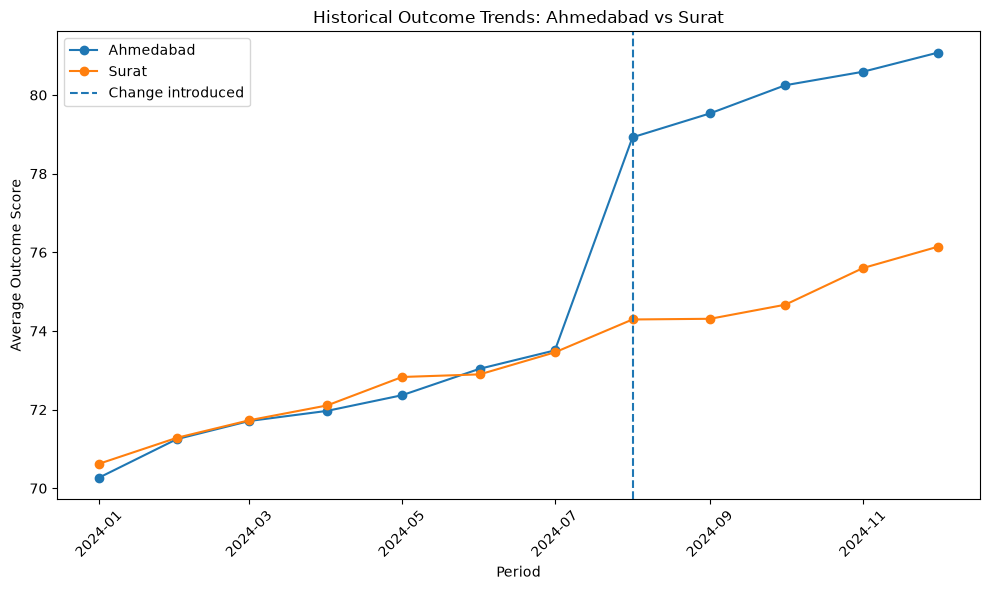

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for region in ["Ahmedabad", "Surat"]:
    region_data = trend_data[
        trend_data["region"] == region
    ]

    plt.plot(
        region_data["period"],
        region_data["outcome_score"],
        marker="o",
        label=region
    )

# Mark the intervention point
change_date = pd.Timestamp("2024-08-01")

plt.axvline(
    change_date,
    linestyle="--",
    label="Change introduced"
)

plt.title("Historical Outcome Trends: Ahmedabad vs Surat")
plt.xlabel("Period")
plt.ylabel("Average Outcome Score")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [24]:
# Calculate average outcome before and after the change
did_summary = (
    historical_df
    .groupby(["treated", "post_change"])["outcome_score"]
    .mean()
    .unstack()
)

print("Average outcome by treatment group and period:")
display(did_summary)

# Control group change
control_change = (
    did_summary.loc[0, 1]
    - did_summary.loc[0, 0]
)

# Treated group change
treatment_change = (
    did_summary.loc[1, 1]
    - did_summary.loc[1, 0]
)

# Difference-in-Differences
did_effect = (
    treatment_change
    - control_change
)

print(
    f"\nControl group change: "
    f"{control_change:.2f} points"
)

print(
    f"Treated group change: "
    f"{treatment_change:.2f} points"
)

print(
    f"Difference-in-Differences effect: "
    f"{did_effect:.2f} points"
)

Average outcome by treatment group and period:


post_change,0,1
treated,,
0,72.132056,75.002925
1,72.015880,80.076428



Control group change: 2.87 points
Treated group change: 8.06 points
Difference-in-Differences effect: 5.19 points


In [25]:
import statsmodels.formula.api as smf

# Difference-in-Differences regression
did_model = smf.ols(
    "outcome_score ~ treated + post_change + treated:post_change",
    data=historical_df
).fit(
    cov_type="HC1"
)

# DiD coefficient
did_coefficient = did_model.params["treated:post_change"]

# 95% confidence interval
did_ci_low, did_ci_high = did_model.conf_int().loc[
    "treated:post_change"
]

# p-value
did_p_value = did_model.pvalues["treated:post_change"]

print(
    f"DiD treatment effect: "
    f"{did_coefficient:.2f} points"
)

print(
    f"95% CI: "
    f"{did_ci_low:.2f} to {did_ci_high:.2f} points"
)

print(
    f"p-value: "
    f"{did_p_value:.4f}"
)

if did_p_value < 0.05:
    print(
        "The DiD effect is statistically significant "
        "at the 5% level."
    )
else:
    print(
        "The DiD effect is not statistically significant "
        "at the 5% level."
    )

DiD treatment effect: 5.19 points
95% CI: 4.72 to 5.66 points
p-value: 0.0000
The DiD effect is statistically significant at the 5% level.


In [26]:
from statsmodels.stats.proportion import proportion_effectsize
from statsmodels.stats.power import NormalIndPower

# Experiment design assumptions
baseline_completion = 0.10
target_completion = 0.14
alpha = 0.05
power = 0.80

# Convert the expected difference into an effect size
effect_size = proportion_effectsize(
    baseline_completion,
    target_completion
)

# Calculate required sample size per group
power_analysis = NormalIndPower()

required_n_per_group = power_analysis.solve_power(
    effect_size=effect_size,
    alpha=alpha,
    power=power,
    ratio=1.0,
    alternative="two-sided"
)

required_n_per_group = int(
    round(required_n_per_group)
)

total_required_n = (
    required_n_per_group * 2
)

print("Power analysis assumptions:")
print(f"Baseline completion rate: {baseline_completion * 100:.1f}%")
print(f"Target completion rate: {target_completion * 100:.1f}%")
print(f"Minimum detectable effect: {(target_completion - baseline_completion) * 100:.1f} percentage points")
print(f"Significance level (alpha): {alpha}")
print(f"Statistical power: {power * 100:.0f}%")

print(
    f"\nRequired sample size per group: "
    f"{required_n_per_group:,}"
)

print(
    f"Total required sample size: "
    f"{total_required_n:,}"
)

Power analysis assumptions:
Baseline completion rate: 10.0%
Target completion rate: 14.0%
Minimum detectable effect: 4.0 percentage points
Significance level (alpha): 0.05
Statistical power: 80%

Required sample size per group: 1,029
Total required sample size: 2,058


## Experiment Design

### Initiative
Personalised Weekly Progress Feedback.

### Hypothesis
Learners who receive personalised weekly progress feedback will have better learning outcomes than learners following the normal process.

### Treatment
Learners receive weekly feedback covering attendance, assignment submission, assessment performance, and areas for improvement.

### Control
Learners continue with the normal learning process without the personalised weekly feedback intervention.

### Primary Metric
Course completion rate.

### Secondary Metric
Average assessment score.

### Supporting Outcome
Dropout rate.

### Guardrail Metrics
- Attendance rate
- Assignment submission rate

### Randomization
Learners were randomly assigned approximately 50/50 to treatment and control groups.

### Sample Size
A power analysis was conducted using:
- Baseline completion rate: 10%
- Target completion rate: 14%
- Minimum detectable effect: 4 percentage points
- Significance level: 5%
- Statistical power: 80%

The required sample size was 1,029 learners per group, or 2,058 learners in total. The synthetic experiment contains 10,000 learners, which is above the required sample size.

### Test Duration
Because course completion is the primary outcome, the experiment should run for one complete course cycle so that learners have enough time to reach the completion outcome. Weekly attendance, assignment submission, and assessment results can be monitored during the experiment.

### Decision Rule
The initiative should be recommended for broader implementation only after considering the estimated treatment effects, 95% confidence intervals, statistical significance, and guardrail outcomes together.

In [27]:
# Assessment score by region and treatment
segment_assessment = (
    analysis_df
    .groupby(["region", "treatment"])["average_assessment"]
    .agg(
        learners="count",
        mean_score="mean"
    )
)

# Reshape treatment groups into columns
regional_scores = (
    segment_assessment["mean_score"]
    .unstack()
)

# Calculate treatment effect within each region
regional_scores["effect"] = (
    regional_scores[1] - regional_scores[0]
)

print("Assessment score by region:")
display(regional_scores)

Assessment score by region:


treatment,0,1,effect
region,,,
Ahmedabad,64.739810,68.079653,3.339843
Rajkot,64.592450,67.820547,3.228097
Surat,64.451632,68.399847,3.948215
Vadodara,64.798715,67.965600,3.166885


In [28]:
# Check whether the treatment effect on assessment score
# differs significantly across regions

interaction_model = smf.ols(
    "average_assessment ~ treatment * C(region)",
    data=analysis_df
).fit()

print(interaction_model.summary())

                            OLS Regression Results                            
Dep. Variable:     average_assessment   R-squared:                       0.044
Model:                            OLS   Adj. R-squared:                  0.044
Method:                 Least Squares   F-statistic:                     66.10
Date:                Sat, 07 Nov 2026   Prob (F-statistic):           1.34e-93
Time:                        00:04:40   Log-Likelihood:                -35121.
No. Observations:               10000   AIC:                         7.026e+04
Df Residuals:                    9992   BIC:                         7.032e+04
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                                      coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
Intercept 

## Experiment Results Summary

### Primary Outcome
The treatment increased the course completion rate from 10.54% to 11.74%, an absolute improvement of 1.20 percentage points. However, the 95% confidence interval for the difference was approximately -0.03 to +2.44 percentage points, which includes zero. Therefore, the completion-rate improvement was not statistically significant at the 5% level.

### Assessment Performance
The treatment increased the average assessment score by approximately 3.47 points. The 95% confidence interval was approximately 3.16 to 3.79 points, and the Welch t-test was statistically significant. This provides strong evidence of an improvement in assessment performance.

### Dropout
The dropout rate decreased by approximately 0.09 percentage points under treatment. The 95% confidence interval included zero, so there is no statistically significant evidence of a reduction in dropout.

### Guardrail Metrics
Treatment improved both attendance and assignment submission rates. Attendance increased by approximately 6.67 percentage points, while assignment submission increased by approximately 3.64 percentage points. Both effects were statistically significant and their confidence intervals were entirely above zero.

### Segment Analysis
Assessment scores were higher in the treatment group across all four regions. The observed effects ranged from approximately 3.17 to 3.95 points. The treatment-by-region interaction terms were not statistically significant, so there is no strong evidence that the assessment-score effect differs by region.

### Overall Experiment Conclusion
The experiment provides strong evidence that the initiative improves assessment performance and supporting engagement measures. However, the primary completion-rate outcome did not show a statistically significant improvement, and the dropout rate did not change significantly. Therefore, the evidence is not sufficient to declare the initiative a clear success on the primary business outcome.

## Final Recommendation

### Decision: EXTEND THE EXPERIMENT

The experiment should be extended rather than immediately rolled out or stopped.

The treatment produced a statistically significant improvement in average assessment score of approximately 3.47 points, along with significant improvements in attendance and assignment submission. The dropout rate did not show a statistically significant increase.

However, the primary outcome, course completion rate, increased by only 1.20 percentage points and its 95% confidence interval included zero. Therefore, the experiment does not yet provide sufficient evidence that the initiative improves course completion.

The recommended decision is to continue testing the initiative for another complete course cycle while monitoring completion rate as the primary outcome and assessment score, attendance, assignment submission, and dropout as supporting outcomes and guardrails.

The next test should also investigate whether the improvement in assessment performance eventually leads to higher completion. If completion improves significantly while the positive assessment and engagement effects remain, the initiative can then be considered for broader implementation.

## Limitations and Causal Assumptions

### Experiment

The A/B experiment relies on random assignment, so the treatment and control groups can be compared as causal groups if the randomization was implemented correctly.

Potential issues that could affect the causal estimate include:

- Incorrect or inconsistent treatment assignment
- Learners not following their assigned treatment
- Contamination between treatment and control groups
- Learners dropping out before enough outcome data is observed
- Missing attendance or activity data
- Duplicate learner or enrolment records
- Changes in how outcomes are recorded during the experiment

The data cleaning process removed duplicate learner-week records and separated structural missing attendance caused by inactivity from genuine missing attendance values.

### Difference-in-Differences

The Difference-in-Differences estimate depends mainly on the parallel-trends assumption. This means that, without the intervention, the treated and control regions would have followed similar outcome trends.

The pre-change trends in Ahmedabad and Surat were broadly similar, although they were not perfectly identical. Therefore, the DiD estimate should be interpreted with some caution.

Other factors that could affect the DiD estimate include region-specific changes occurring at the same time as the intervention, differences between the regions, changes in learner composition, and other policies or events that were not included in the data.

### Synthetic Data Limitation

The experiment and historical datasets used in this project are synthetic datasets generated for analysis because an actual experiment dataset was not supplied on the project page. Therefore, the numerical treatment effects should not be interpreted as real-world effects for an actual coaching institute.

The purpose of the analysis is to demonstrate the experiment design, data-quality checks, statistical methods, causal reasoning, and decision-making process described in the project requirements.

## Key Takeaways

1. The experiment groups were well balanced, with no evidence of sample ratio mismatch.
2. Duplicate learner-week records were identified and removed before analysis.
3. Most missing attendance values were structural and occurred after learners became inactive. Genuine missing attendance among active learners was limited.
4. The treatment increased average assessment scores by approximately 3.47 points, with a statistically significant effect.
5. Course completion increased by approximately 1.20 percentage points, but the confidence interval included zero, so the improvement was not statistically significant.
6. Dropout did not change significantly.
7. Attendance and assignment submission both improved significantly under treatment.
8. Assessment-score improvements were observed across all four regions, with no statistically significant evidence that the treatment effect differed by region.
9. The Difference-in-Differences analysis estimated an approximately 5.19-point improvement associated with the historical change in Ahmedabad relative to Surat, under the parallel-trends assumption.
10. Based on the experiment results, the recommended decision is to extend the experiment rather than immediately roll out or stop the initiative.

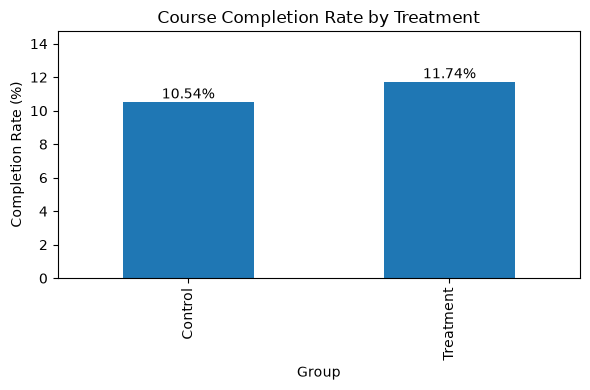

In [29]:
# Completion rate by treatment

completion_plot = (
    analysis_df.groupby("treatment")["completion_binary"]
    .mean()
    .mul(100)
)

completion_plot.index = ["Control", "Treatment"]

ax = completion_plot.plot(
    kind="bar",
    figsize=(6, 4),
    title="Course Completion Rate by Treatment"
)

ax.set_xlabel("Group")
ax.set_ylabel("Completion Rate (%)")
ax.set_ylim(0, max(completion_plot) + 3)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

plt.tight_layout()
plt.show()

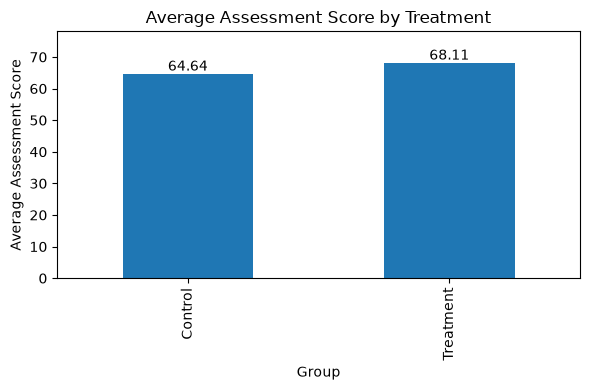

In [30]:
# Average assessment score by treatment

assessment_plot = (
    analysis_df.groupby("treatment")["average_assessment"]
    .mean()
)

assessment_plot.index = ["Control", "Treatment"]

ax = assessment_plot.plot(
    kind="bar",
    figsize=(6, 4),
    title="Average Assessment Score by Treatment"
)

ax.set_xlabel("Group")
ax.set_ylabel("Average Assessment Score")
ax.set_ylim(0, max(assessment_plot) + 10)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f")

plt.tight_layout()
plt.show()

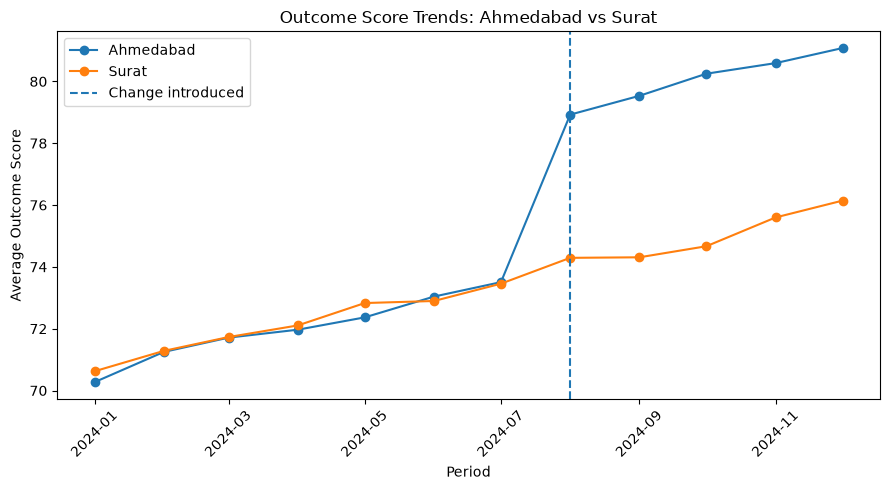

In [31]:
# Outcome trends for Difference-in-Differences analysis

plt.figure(figsize=(9, 5))

for region in ["Ahmedabad", "Surat"]:
    region_data = trend_data[trend_data["region"] == region]
    
    plt.plot(
        region_data["period"],
        region_data["outcome_score"],
        marker="o",
        label=region
    )

# Mark the start of the intervention
plt.axvline(
    pd.Timestamp("2024-08-01"),
    linestyle="--",
    label="Change introduced"
)

plt.title("Outcome Score Trends: Ahmedabad vs Surat")
plt.xlabel("Period")
plt.ylabel("Average Outcome Score")
plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [32]:
from pathlib import Path

# Create outputs folder if it does not already exist
output_dir = Path("../outputs")
output_dir.mkdir(exist_ok=True)

# Save completion summary
completion_summary.to_csv(
    output_dir / "completion_summary.csv"
)

# Save dropout summary
dropout_summary.to_csv(
    output_dir / "dropout_summary.csv"
)

# Save regional completion results
segment_completion.to_csv(
    output_dir / "regional_completion.csv"
)

# Save regional assessment results
regional_scores.to_csv(
    output_dir / "regional_assessment_scores.csv"
)

# Save DiD summary
did_summary.to_csv(
    output_dir / "did_summary.csv"
)

print("Key analysis tables saved successfully.")

Key analysis tables saved successfully.
